# **Assignment 02**
# MD. Mahmood Ul Quaium
# CSE 080 08541

# PART A — Exploratory Data Analysis & Preprocessing :

Q1 Load the dataset and display:

  (a) the first 5 rows using df.head()

  (b) the data types and non-null counts using df.info()

  (c) the number of missing values per column using df.isnull().sum()
  

Then fill missing values in numeric columns using the column median. Print the shape
of the cleaned dataframe.

In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score


from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree



In [4]:
df = pd.read_csv("/content/knn_tree_students - knn_tree_students.csv")


print(df.head())

print(df.info())

print(df.isnull().sum())

numeric_cols = [
    "cgpa",
    "study_hours_per_week",
    "attendance_percent",
    "sleep_hours_per_night"
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Shape of cleaned dataframe:", df.shape)

  student_id  gender department  year_of_study   home_city  cgpa  \
0       K400  Female        CSE              2      Sylhet  3.18   
1       K401  Female        EEE              1  Chittagong  3.17   
2       K402    Male        CSE              3      Sylhet  3.67   
3       K403    Male        EEE              2       Dhaka  3.10   
4       K404    Male        EEE              4       Dhaka  2.62   

   study_hours_per_week  attendance_percent  sleep_hours_per_night  \
0                  19.5                78.4                    4.0   
1                   NaN                81.4                    7.7   
2                  20.0                82.2                    6.1   
3                   5.7                47.4                    6.6   
4                  17.6                81.3                    8.9   

   assignment_score  quiz_average  tuition_fee     scholarship  \
0              75.7          89.8        30000  No_Scholarship   
1              60.8          71.8     

Q2 Encode categorical features for modelling:

  (a) Apply One-Hot Encoding to department, home_city, scholarship, and
participates_in_clubs. Use drop_first=True to avoid multicollinearity.

  (b) Apply Label Encoding to gender (Male=1, Female=0).
  
  (c) Drop student_id. Print the final column list.

In [5]:
df = pd.get_dummies(df,columns=[
        "department",
        "home_city",
        "scholarship",
        "participates_in_clubs"
    ],
    drop_first=True
)

le = LabelEncoder()
df["gender"] = le.fit_transform(df["gender"])
print(df["gender"].value_counts())

df = df.drop("student_id", axis=1)

print("Final columns:")
print(df.columns.tolist())

gender
1    39
0    36
Name: count, dtype: int64
Final columns:
['gender', 'year_of_study', 'cgpa', 'study_hours_per_week', 'attendance_percent', 'sleep_hours_per_night', 'assignment_score', 'quiz_average', 'tuition_fee', 'passed', 'department_BBA', 'department_CSE', 'department_EEE', 'department_Pharmacy', 'home_city_Dhaka', 'home_city_Khulna', 'home_city_Rajshahi', 'home_city_Sylhet', 'scholarship_No_Scholarship', 'scholarship_Partial', 'participates_in_clubs_Yes']


Q3 Split the data into features X and target y (passed). Perform an 80/20 train-test split
with random_state=42 and stratify=y. Print the class distribution in both the training
and test sets to confirm balance.

In [6]:
X = df.drop("passed", axis=1)
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training class ")
print(y_train.value_counts())

print("\nTesting class ")
print(y_test.value_counts())

Training class 
passed
1    34
0    26
Name: count, dtype: int64

Testing class 
passed
1    9
0    6
Name: count, dtype: int64


Q4 Apply StandardScaler to X_train and X_test (fit on train only). Explain in a comment
why we fit the scaler on the training set only and not on the full dataset. What problem

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (60, 20)
X_test_scaled shape: (15, 20)


Q5 Produce a correlation heatmap using seaborn for the numeric columns: cgpa,
study_hours_per_week, attendance_percent, assignment_score, quiz_average, and
passed. Identify and state (in a comment) the two features most positively correlated
with passed.

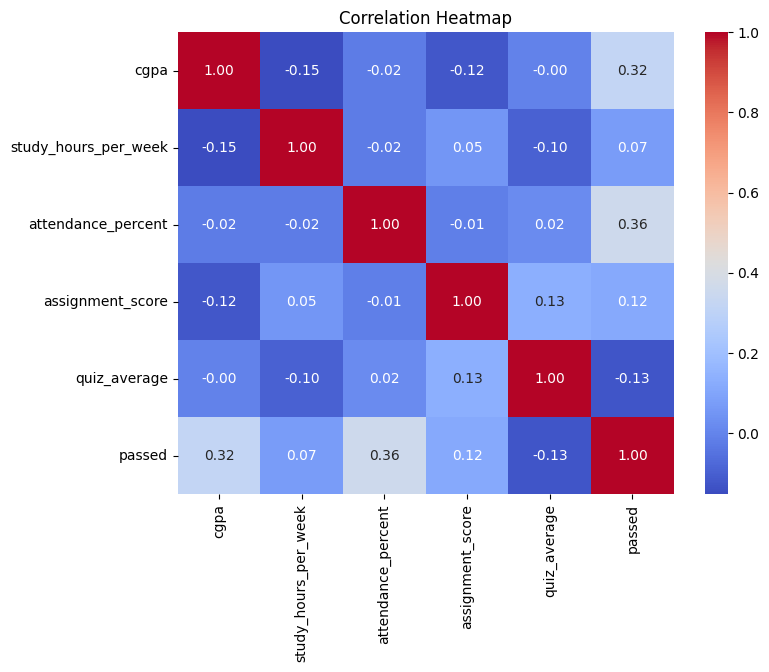

In [8]:
corr_cols = [
    "cgpa",
    "study_hours_per_week",
    "attendance_percent",
    "assignment_score",
    "quiz_average",
    "passed"
]
corr = df[corr_cols].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## PART B — KNN Classifier

Q6 Train a KNeighborsClassifier with k=5 on the scaled training data. Predict on the test
set and print:

  (a) Accuracy

  (b) Classification report (precision, recall, F1-score for each class)

In [9]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         6
           1       0.75      1.00      0.86         9

    accuracy                           0.80        15
   macro avg       0.88      0.75      0.76        15
weighted avg       0.85      0.80      0.78        15



Q7 Find the optimal value of k by testing k = 1, 3, 5, 7, 9, 11, 13, 15. For each k, record both
the training accuracy and the test accuracy. Plot both curves on the same graph (x-axis:
k, y-axis: accuracy). Label the curves 'Train' and 'Test'. Mark the k with the highest test
accuracy. State the best k and its test accuracy in a comment.

k = 1: Train Accuracy = 100.00%, Test Accuracy = 53.33%
k = 3: Train Accuracy = 76.67%, Test Accuracy = 80.00%
k = 5: Train Accuracy = 70.00%, Test Accuracy = 80.00%
k = 7: Train Accuracy = 68.33%, Test Accuracy = 86.67%
k = 9: Train Accuracy = 66.67%, Test Accuracy = 80.00%
k = 11: Train Accuracy = 60.00%, Test Accuracy = 73.33%
k = 13: Train Accuracy = 66.67%, Test Accuracy = 66.67%
k = 15: Train Accuracy = 60.00%, Test Accuracy = 66.67%


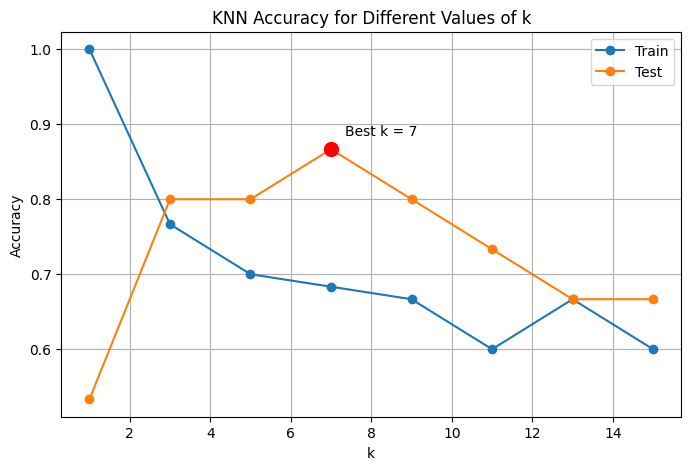

In [10]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15]

train_accuracies = []
test_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    train_acc = knn.score(X_train_scaled, y_train)
    test_acc = knn.score(X_test_scaled, y_test)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"k = {k}: Train Accuracy = {train_acc:.2%}, "
          f"Test Accuracy = {test_acc:.2%}")


best_index = test_accuracies.index(max(test_accuracies))
best_k = k_values[best_index]
best_test_accuracy = test_accuracies[best_index]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(k_values, train_accuracies, marker='o', label='Train')
plt.plot(k_values, test_accuracies, marker='o', label='Test')


plt.scatter(best_k, best_test_accuracy,
            color='red', s=100, zorder=5)

plt.annotate(
    f'Best k = {best_k}',
    (best_k, best_test_accuracy),
    xytext=(10, 10),
    textcoords='offset points'
)

plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy for Different Values of k')
plt.legend()
plt.grid(True)
plt.show()


Q8 Repeat Q6 without scaling (use the raw X_train and X_test). Compare the test accuracy
with and without scaling. Explain in a comment (2–3 sentences) why scaling affects
KNN performance but does not affect a Decision Tree.

In [11]:
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)

test_accuracy_raw = knn_raw.score(X_test, y_test)

print(f"Test Accuracy without scaling: {test_accuracy_raw:.2%}")
print(f"Test Accuracy with scaling: 80.00%")

Test Accuracy without scaling: 53.33%
Test Accuracy with scaling: 80.00%


# KNN uses distance, so different feature scales can change the distance and affect its performance. Decision Trees use feature-based split rules, not distance, so scaling usually does not affect their performance.



# Without scaling, features with larger numerical values can dominate the distance calculation in KNN, so the model may give less importance to smaller-scale features.

Q9 Use cross-validation to evaluate KNN (k=best k from Q7):

  (a) Perform 5-fold cross-validation on the full scaled dataset using cross_val_score.

  (b) Print the accuracy for each fold and the mean ± standard deviation.
   
  (c) Explain in a comment what high standard deviation across folds would indicate.

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

knn = KNeighborsClassifier(n_neighbors=7)

cv_scores = cross_val_score(
    knn,
    X_scaled,
    y,
    cv=5,
    scoring='accuracy'
)

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i} Accuracy: {score:.2%}")

print(f"\nMean Accuracy: {cv_scores.mean():.2%}")
print(f"Standard Deviation: {cv_scores.std():.2%}")

Fold 1 Accuracy: 46.67%
Fold 2 Accuracy: 66.67%
Fold 3 Accuracy: 73.33%
Fold 4 Accuracy: 60.00%
Fold 5 Accuracy: 53.33%

Mean Accuracy: 60.00%
Standard Deviation: 9.43%


# A high standard deviation means the KNN model's accuracy changes significantly when tested on different parts of the dataset, indicating that the model's performance is less stable.

## PART C — Decision Tree Classifier

Q10 Train a DecisionTreeClassifier with criterion='gini' and random_state=42 (no depth
limit) on the unscaled training data. Print the training accuracy and test accuracy.
Does the tree overfit? Justify your answer in a comment.

In [13]:
tree = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)
tree.fit(X_train, y_train)

train_accuracy = tree.score(X_train, y_train)
test_accuracy = tree.score(X_test, y_test)

print(f"Training Accuracy: {train_accuracy:.2%}")
print(f"Test Accuracy: {test_accuracy:.2%}")


Training Accuracy: 100.00%
Test Accuracy: 80.00%


## The tree is overfitting because the training accuracy is 100%,
## while the test accuracy is only 80%. This large difference shows
## that the tree learned the training data too closely and does not
## generalize as well to unseen data.

Q11 Visualise the trained decision tree using plot_tree() from sklearn.tree. Set
max_depth=3 in plot_tree for readability (not in the model).

  (a) What is the root node feature?

  (b) What Gini impurity does the root node report?
  
State both answers in a code comment.

# (a) Root node feature = cgpa
# (b) Root node Gini impurity = 0.4911

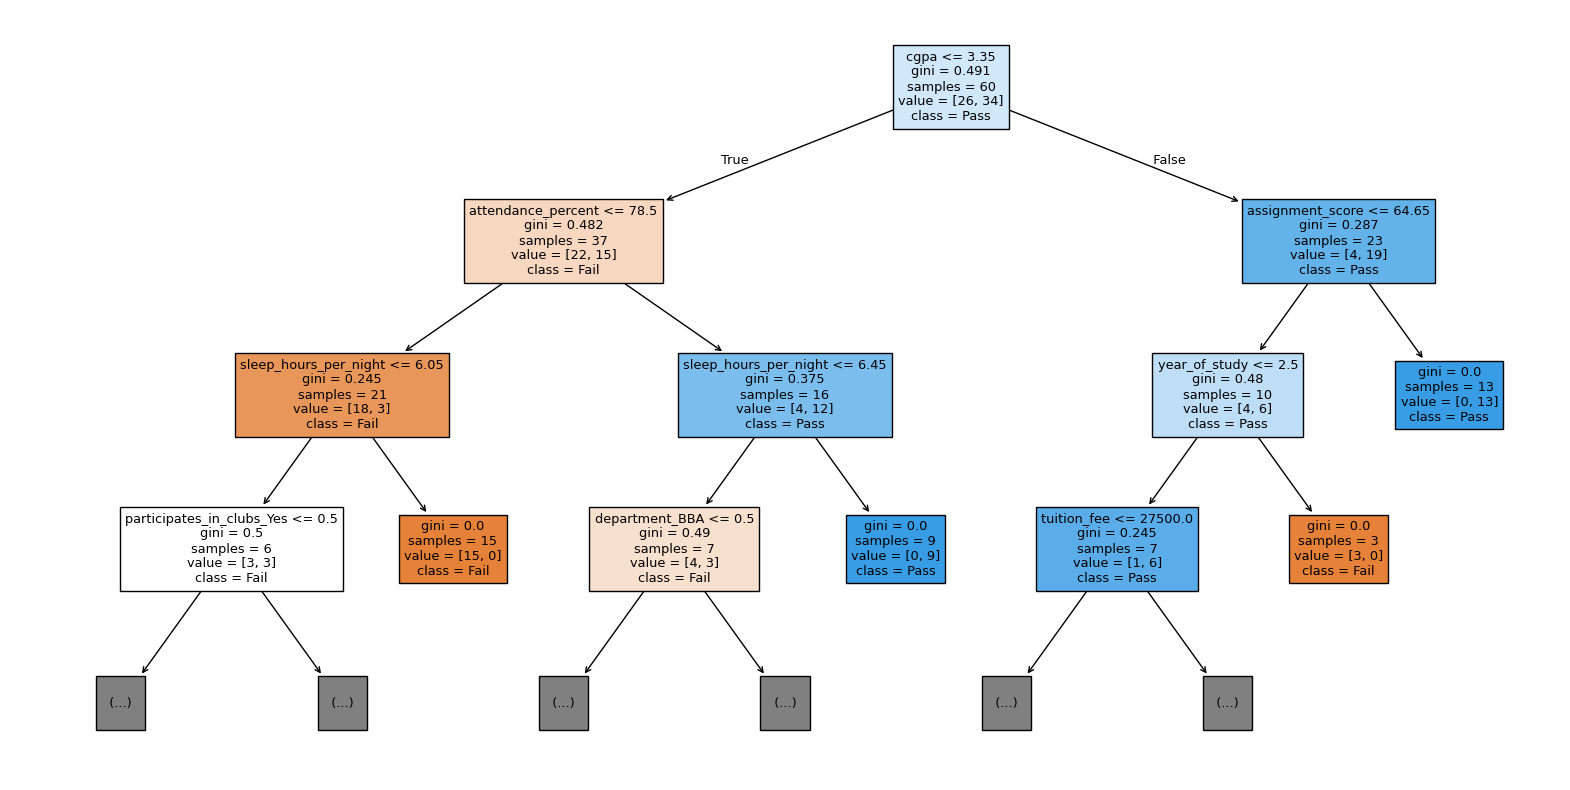

In [14]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    max_depth=3
)

plt.show()



Q12 Control overfitting by tuning max_depth. Test max_depth = 2, 3, 4, 5, 6, 8, None. For
each depth, record training accuracy and test accuracy. Plot both curves (similar to
[3 marks]
Q7). State the best max_depth and the corresponding test accuracy in a comment.

max_depth=2: Train Accuracy=81.67%, Test Accuracy=93.33%
max_depth=3: Train Accuracy=88.33%, Test Accuracy=93.33%
max_depth=4: Train Accuracy=98.33%, Test Accuracy=86.67%
max_depth=5: Train Accuracy=100.00%, Test Accuracy=80.00%
max_depth=6: Train Accuracy=100.00%, Test Accuracy=80.00%
max_depth=8: Train Accuracy=100.00%, Test Accuracy=80.00%
max_depth=None: Train Accuracy=100.00%, Test Accuracy=80.00%


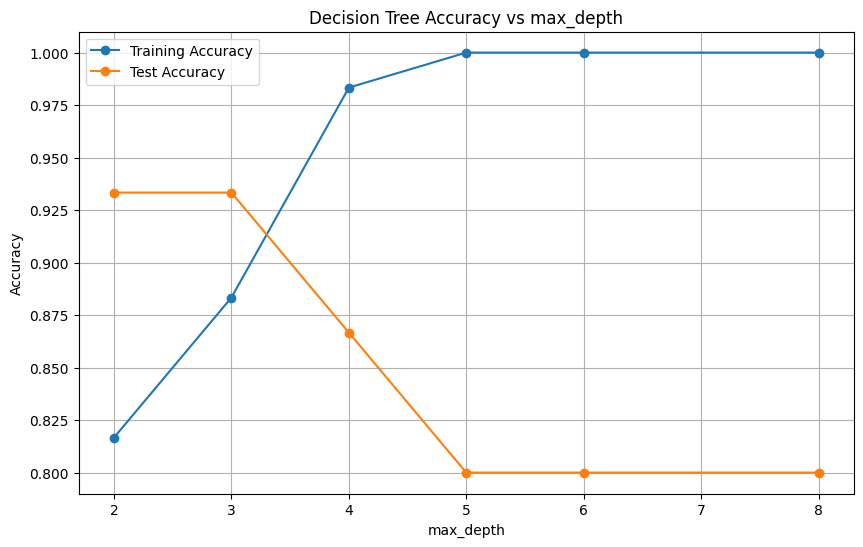

In [15]:
depths = [2, 3, 4, 5, 6, 8, None]

train_accuracies = []
test_accuracies = []

for depth in depths:

    tree = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_acc = tree.score(X_train, y_train)
    test_acc = tree.score(X_test, y_test)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"max_depth={depth}: "
          f"Train Accuracy={train_acc:.2%}, "
          f"Test Accuracy={test_acc:.2%}")


# Plot
plt.figure(figsize=(10, 6))

plt.plot(depths, train_accuracies,
         marker='o', label='Training Accuracy')

plt.plot(depths, test_accuracies,
         marker='o', label='Test Accuracy')

plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy vs max_depth")
plt.legend()
plt.grid(True)

plt.show()



best_index = test_accuracies.index(max(test_accuracies))
best_depth = depths[best_index]
best_test_accuracy = test_accuracies[best_index]


Q13 Using the best max_depth from Q12:

(a) Plot the feature importance bar chart (top 10 features).

(b) State the top 3 most important features in a comment.

(c) Print the full classification report.

(d) Compare the Decision Tree's best test accuracy with the KNN best test accuracy

(from Q7). Which model performs better on this dataset, and why might that be?
Answer in 2–3 sentences in a comment.

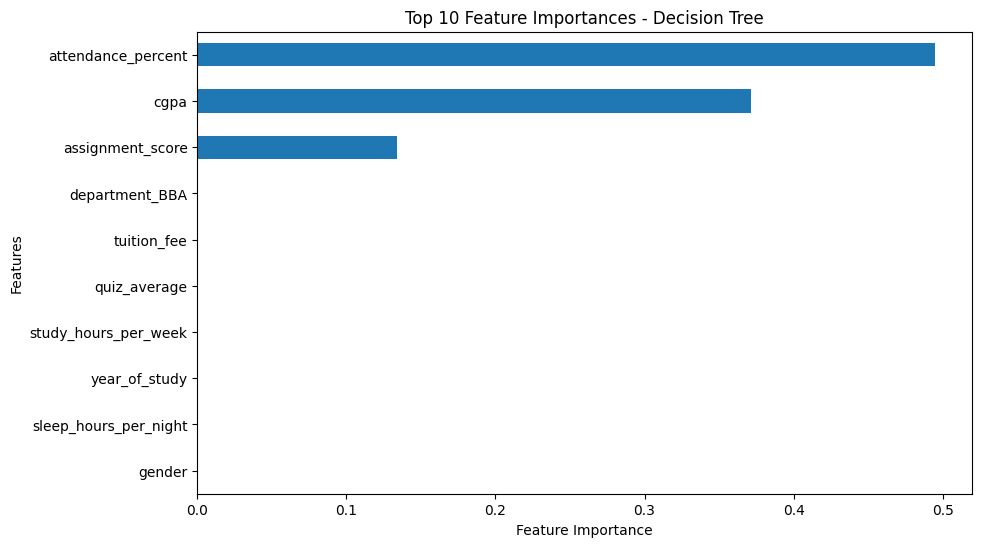

Top 3 Important Features:
attendance_percent    0.495051
cgpa                  0.371207
assignment_score      0.133742
dtype: float64

Classification Report:
              precision    recall  f1-score   support

        Fail       0.86      1.00      0.92         6
        Pass       1.00      0.89      0.94         9

    accuracy                           0.93        15
   macro avg       0.93      0.94      0.93        15
weighted avg       0.94      0.93      0.93        15



In [16]:
best_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=2,
    random_state=42
)

best_tree.fit(X_train, y_train)



feature_importance = pd.Series(
    best_tree.feature_importances_,
    index=X.columns
)

top_10 = feature_importance.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

top_10.sort_values().plot(
    kind='barh'
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Feature Importances - Decision Tree")
plt.show()



top_3 = feature_importance.sort_values(
    ascending=False
).head(3)

print("Top 3 Important Features:")
print(top_3)




y_pred = best_tree.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fail", "Pass"]
))




# Best Decision Tree Test Accuracy = 93.33%
# Best KNN Test Accuracy = 86.67%

# Decision Tree performs better than KNN by 6.66 percentage points.
# The Decision Tree can learn useful threshold-based relationships
# such as attendance and CGPA, while KNN depends on distance between
# data points.